# Mapping stability across the parameter surface

The selection frequency of a candidate setting across repeated histories is:

$$
\widehat\pi(\theta)=\frac{1}{M}\sum_{m=1}^{M}\mathbf 1\{\widehat\theta_m=\theta\}.
$$

Here, $M$ is the number of expanding histories, $m$ identifies one history, $\widehat\theta_m$ is its selected setting, $\mathbf 1\{\cdot\}$ is the indicator function, and $\widehat\pi(\theta)$ is the observed selection share of setting $\theta$.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
from itertools import product
import sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
from IPython.display import Image
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
DATA_URL = 'https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip'
DATA_DIR = ROOT / 'data' / 'public' / 'binance'
DATA_PATH = ensure_dataset(ROOT, 'binance_btcusdt')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
public_columns = ['Open time', 'Open', 'High', 'Low', 'Close', 'Volume', 'Close time', 'Quote volume', 'Trades', 'Buyer base volume', 'Buyer quote volume', 'Unused']
raw = pd.read_csv(DATA_PATH, compression='zip', header=None, names=public_columns, nrows=None)
raw['time'] = pd.to_datetime(raw['Open time'], unit='ms', utc=True).dt.tz_convert(None)
raw = raw.rename(columns={'Close': 'close', 'Volume': 'volume', 'Quote volume': 'quote_volume', 'Trades': 'trades'})
raw = raw.sort_values('time').drop_duplicates('time').reset_index(drop=True)
from RiskLabAI.backtest.validation import PurgedKFold
from RiskLabAI.optimization.hyper_parameter_tuning import SampleWeightedPipeline, clf_hyper_fit
FIGURES = ROOT / 'outputs' / 'figures' / '18_hyperparameter_selection'
TABLES = ROOT / 'outputs' / 'tables' / '18_hyperparameter_selection'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
minute_data = raw.set_index('time')
bars = pd.DataFrame({'Close': minute_data['close'].resample('15min').last(), 'Volume': minute_data['volume'].resample('15min').sum(), 'Quote volume': minute_data['quote_volume'].resample('15min').sum(), 'Trades': minute_data['trades'].resample('15min').sum()}).dropna()
log_close = np.log(bars['Close'])
one_bar_return = log_close.diff()
expected_15 = bars['Close'].ewm(span=15, adjust=False).mean()
expected_55 = bars['Close'].ewm(span=55, adjust=False).mean()
feature_frame = pd.DataFrame({'Previous return': one_bar_return.shift(1), 'Distance from EWM 15': (np.log(bars['Close']) - np.log(expected_15)).shift(1), 'Distance from EWM 55': (np.log(bars['Close']) - np.log(expected_55)).shift(1), 'One-hour return': log_close.diff(4).shift(1), 'Past volatility': one_bar_return.shift(1).rolling(16).std(), 'Log volume change': np.log1p(bars['Volume']).diff().shift(1)})
label_horizon = 8
forward_return = (log_close.shift(-label_horizon) - log_close).rename('Forward return')
direction = forward_return.gt(0).where(forward_return.notna()).astype('Int64').rename('Direction')
end_time = bars.index.to_series().shift(-label_horizon).rename('End time')
public_frame = pd.concat([feature_frame, direction, forward_return, end_time], axis=1).dropna()
public_x = public_frame[feature_frame.columns].astype(float)
public_y = public_frame['Direction'].astype(int)
public_forward_return = public_frame['Forward return'].astype(float)
event_times = public_frame['End time']
absolute_return_weight = public_forward_return.abs()
sample_weight = (absolute_return_weight / absolute_return_weight.median()).clip(lower=0.25, upper=4.0)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151', 'muted': '#94A3B8'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')

def configuration_name(kernel, penalty):
    return f'{kernel.upper()}, C={penalty:g}'

def make_model(kernel, penalty):
    return Pipeline([('scale', StandardScaler()), ('svc', SVC(kernel=kernel, C=float(penalty), gamma='scale'))])

def fit_and_score(kernel, penalty, data, labels, train_indices, test_indices, weights=None):
    model = make_model(kernel, penalty)
    fit_arguments = {}
    if weights is not None:
        fit_arguments['svc__sample_weight'] = weights.iloc[train_indices].to_numpy()
    model.fit(data.iloc[train_indices], labels.iloc[train_indices], **fit_arguments)
    predictions = model.predict(data.iloc[test_indices])
    return {'F1': f1_score(labels.iloc[test_indices], predictions, zero_division=0), 'Precision': precision_score(labels.iloc[test_indices], predictions, zero_division=0), 'Recall': recall_score(labels.iloc[test_indices], predictions, zero_division=0)}

def purged_configuration_scores(data, labels, times, configurations, n_splits=5, embargo=0.01, weights=None):
    splitter = PurgedKFold(n_splits=n_splits, times=times, embargo=embargo)
    splits = list(splitter.split(data, labels))
    records = []
    for order, (kernel, penalty) in enumerate(configurations):
        fold_scores = []
        train_sizes = []
        removals = []
        for train_indices, test_indices in splits:
            values = fit_and_score(kernel, penalty, data, labels, train_indices, test_indices, weights)
            fold_scores.append(values['F1'])
            train_sizes.append(len(train_indices))
            removals.append(len(data) - len(test_indices) - len(train_indices))
        records.append({'Order': order, 'Configuration': configuration_name(kernel, penalty), 'Kernel': kernel, 'C': float(penalty), 'Mean F1': float(np.mean(fold_scores)), 'F1 spread': float(np.std(fold_scores, ddof=1)), 'Smallest fold F1': float(np.min(fold_scores)), 'Largest fold F1': float(np.max(fold_scores)), 'Mean training observations': float(np.mean(train_sizes)), 'Mean removed observations': float(np.mean(removals))})
    return pd.DataFrame(records)

def ordinary_configuration_scores(data, labels, times, configurations, n_splits=5, weights=None):
    splits = list(KFold(n_splits=n_splits, shuffle=False).split(data))
    records = []
    for order, (kernel, penalty) in enumerate(configurations):
        fold_scores = []
        for train_indices, test_indices in splits:
            fold_scores.append(fit_and_score(kernel, penalty, data, labels, train_indices, test_indices, weights)['F1'])
        records.append({'Order': order, 'Configuration': configuration_name(kernel, penalty), 'Kernel': kernel, 'C': float(penalty), 'Mean F1': float(np.mean(fold_scores)), 'F1 spread': float(np.std(fold_scores, ddof=1)), 'Smallest fold F1': float(np.min(fold_scores)), 'Largest fold F1': float(np.max(fold_scores))})
    return pd.DataFrame(records)

def selected_row(frame):
    ordered = frame.sort_values(['Mean F1', 'Order'], ascending=[False, True])
    return ordered.iloc[0]

def residual_overlap_count(train_indices, test_indices, times):
    allowed = PurgedKFold.filtered_training_indices_with_embargo(times, times.iloc[test_indices], embargo_fraction=0, continous_test_times=True)
    allowed_positions = set(times.index.get_indexer(allowed.index).tolist())
    return sum((int(int(index) not in allowed_positions) for index in train_indices))
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Expanding-History Selections

,Window,Observations,History ends,Selected kernel,Selected C,Best mean F1,Second mean F1,Score margin
0,1,900,2021-01-10 13:00:00,linear,0.01,0.724676,0.724676,0
1,2,1200,2021-01-13 16:00:00,rbf,0.01,0.697182,0.555224,0.141959
2,3,1500,2021-01-16 19:00:00,linear,0.01,0.691662,0.691662,0
3,4,1800,2021-01-19 22:00:00,rbf,0.01,0.690645,0.633695,0.056951
4,5,2100,2021-01-23 01:00:00,rbf,10,0.523597,0.513665,0.009933
5,6,2400,2021-01-26 04:00:00,rbf,10,0.496329,0.492691,0.003639
6,7,2951,2021-01-31 21:45:00,rbf,10,0.518038,0.498818,0.019221


,Window,Observations,Configuration,Kernel,C,Mean F1,F1 spread
0,1,900,"LINEAR, C=0.01",linear,0.01,0.724676,0.049069
1,1,900,"LINEAR, C=0.1",linear,0.10,0.724676,0.049069
2,1,900,"LINEAR, C=1",linear,1,0.724676,0.049069
3,1,900,"LINEAR, C=10",linear,10,0.724676,0.049069
4,1,900,"RBF, C=0.01",rbf,0.01,0.724676,0.049069
5,1,900,"RBF, C=0.1",rbf,0.10,0.705294,0.062310
6,1,900,"RBF, C=1",rbf,1,0.596173,0.130682
7,1,900,"RBF, C=10",rbf,10,0.540607,0.100195
8,2,1200,"LINEAR, C=0.01",linear,0.01,0.548148,0.249871
9,2,1200,"LINEAR, C=0.1",linear,0.10,0.537864,0.236456


,Selected kernel,Selected C,Selections,Selection share
0,linear,0.01,2,0.285714
1,rbf,0.01,2,0.285714
2,rbf,10,3,0.428571


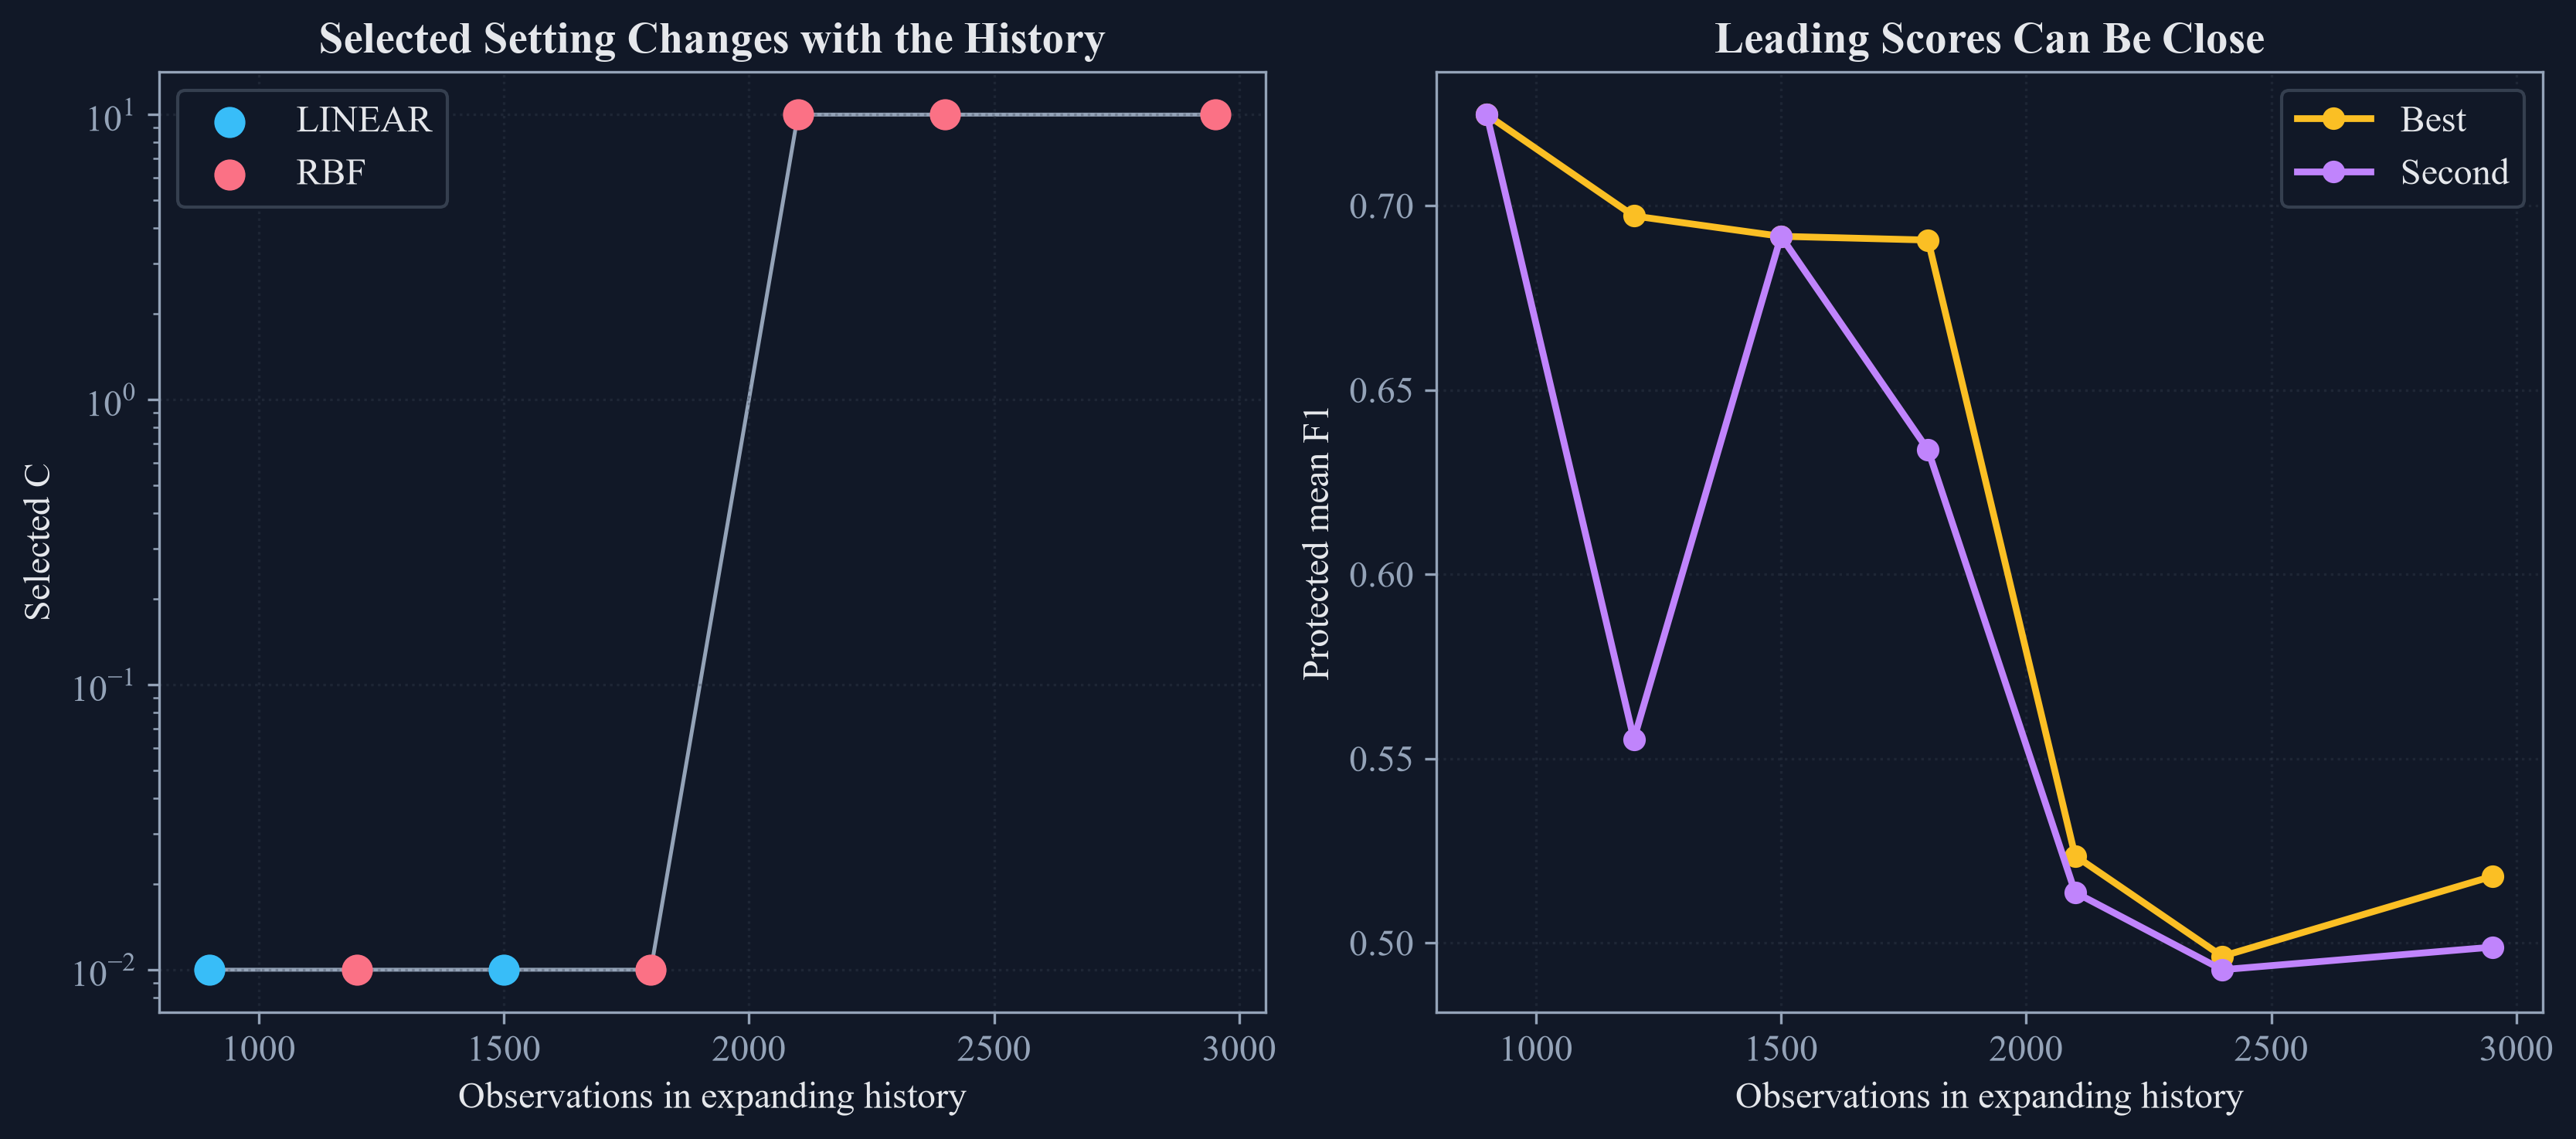

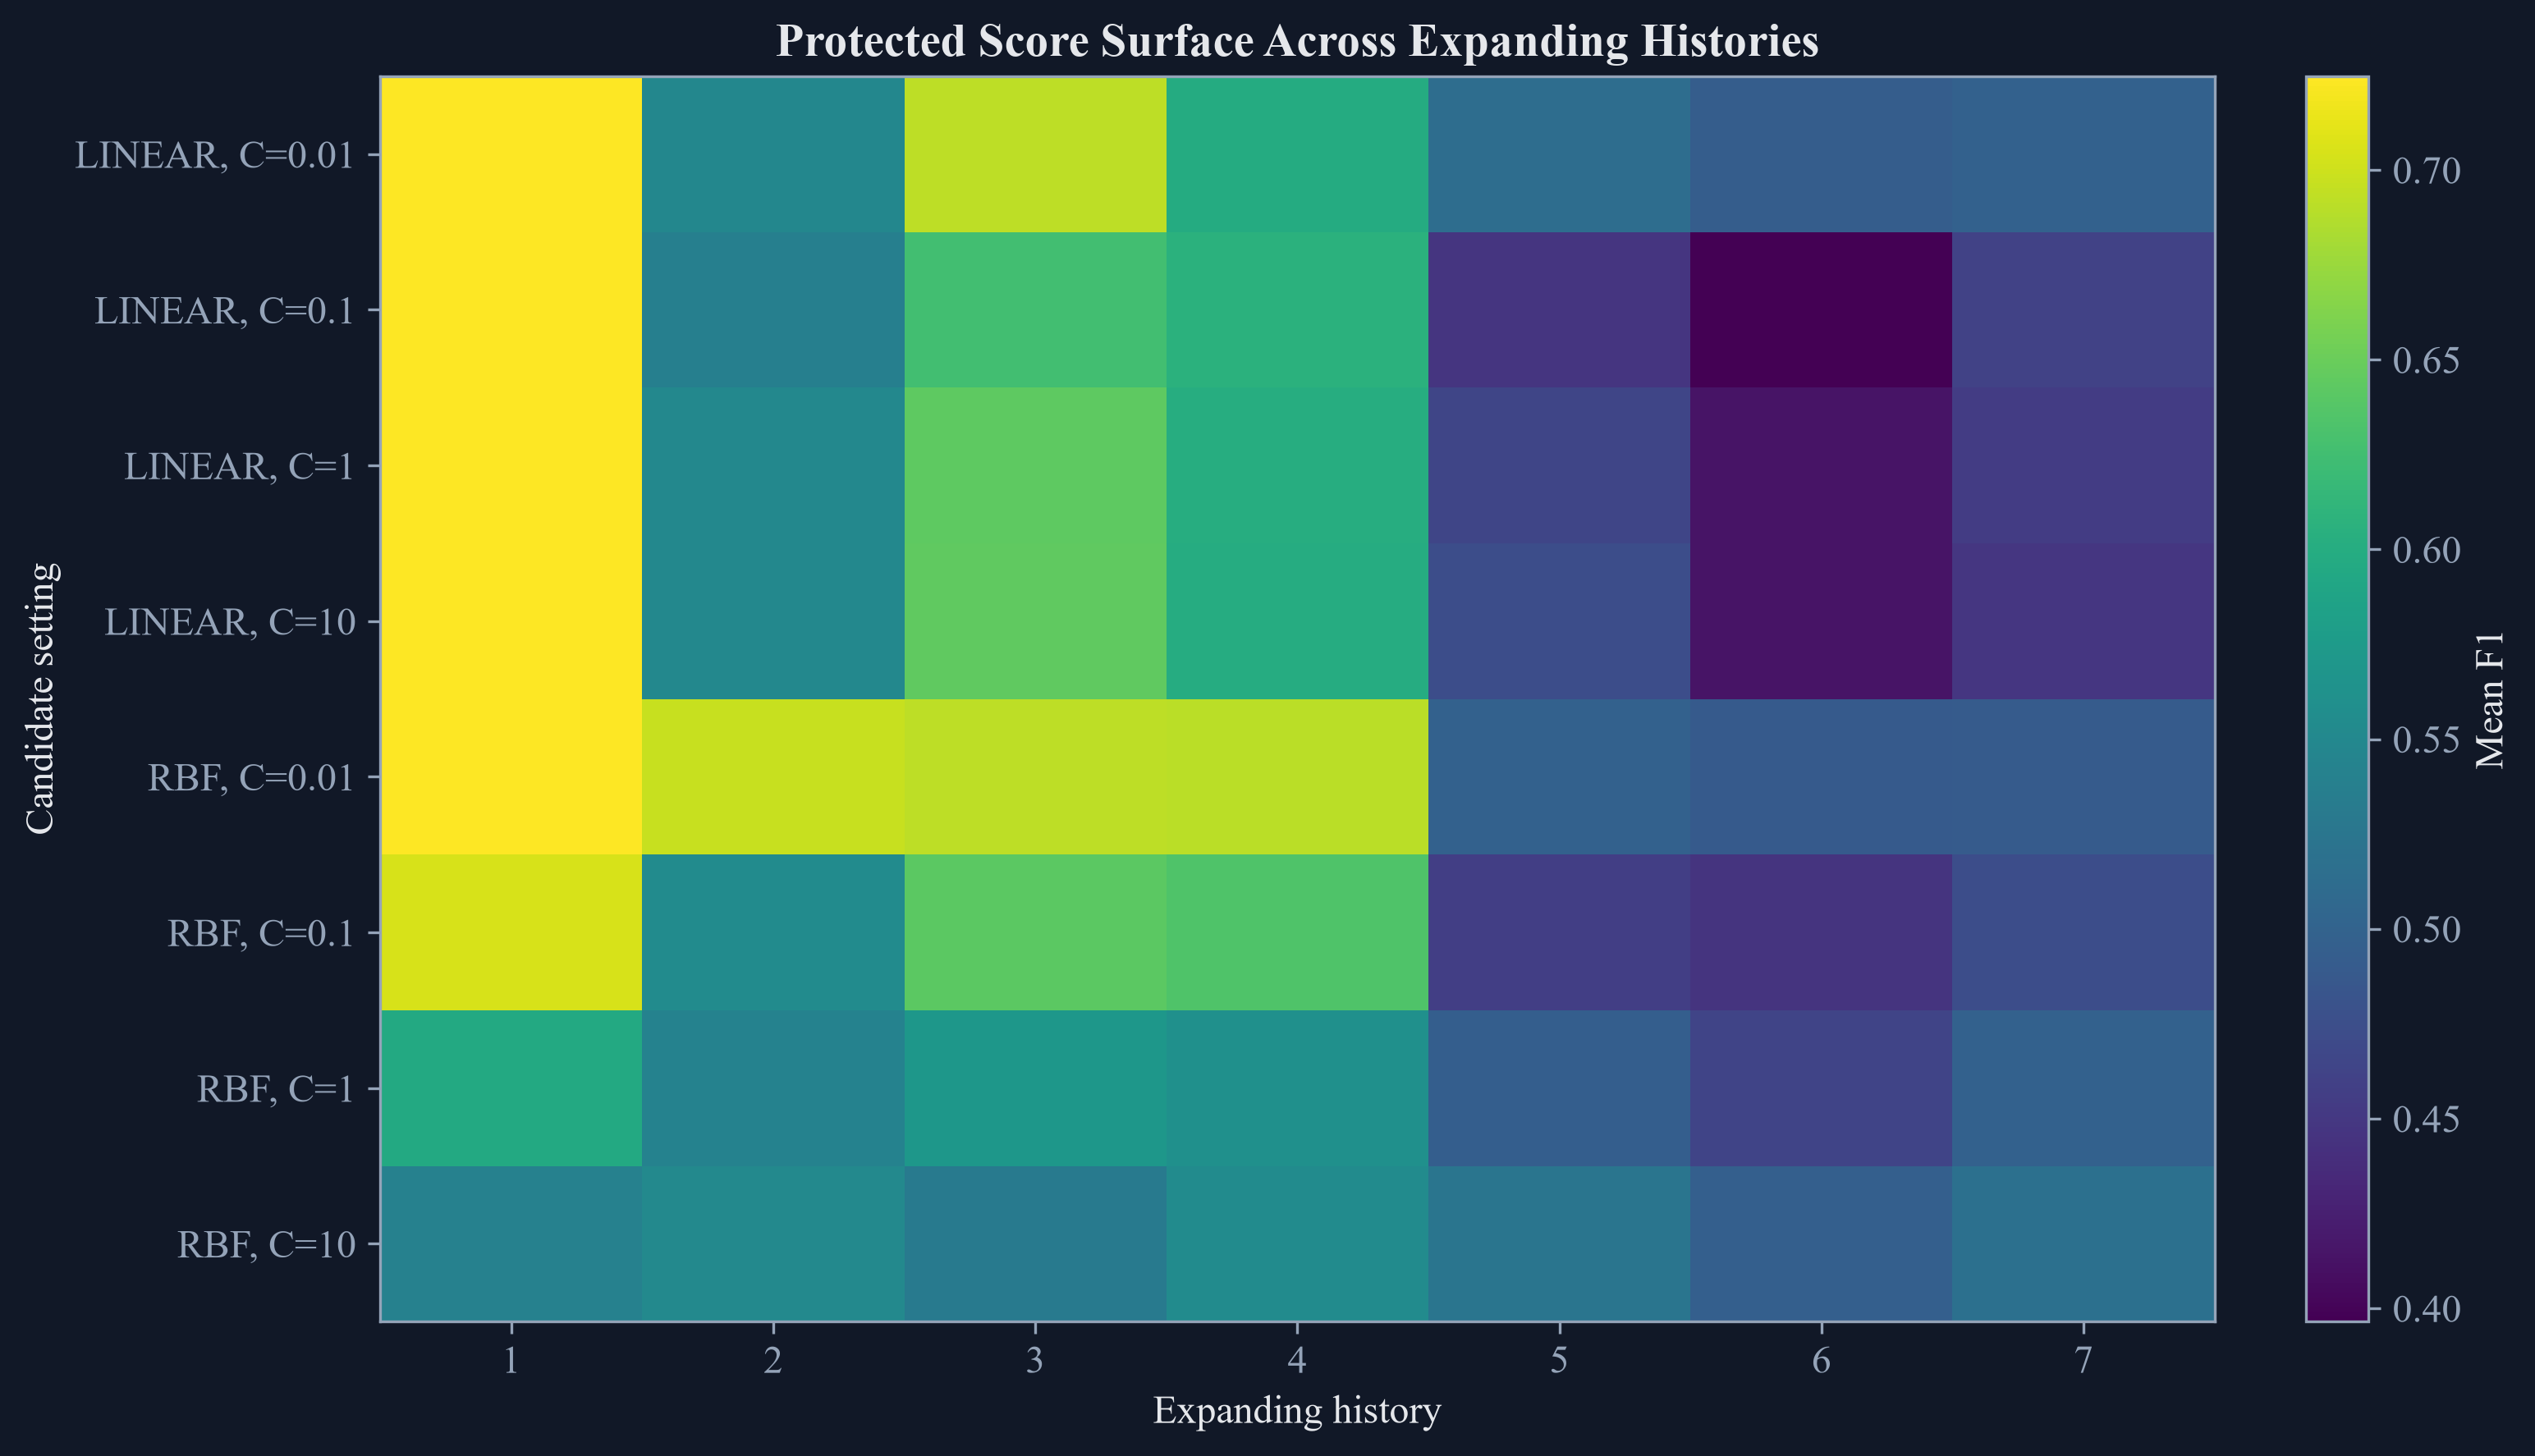

In [2]:
stability_configurations = [(kernel, penalty) for kernel, penalty in product(["linear", "rbf"], [0.01, 0.1, 1.0, 10.0])]
history_sizes = [900, 1200, 1500, 1800, 2100, 2400, len(public_x)]
history_records = []
history_surface_records = []
for window, history_size in enumerate(history_sizes, start=1):
    history_x = public_x.iloc[:history_size]
    history_y = public_y.iloc[:history_size]
    history_times = event_times.iloc[:history_size]
    history_weights = sample_weight.iloc[:history_size]
    surface = purged_configuration_scores(history_x, history_y, history_times, stability_configurations, n_splits=4, embargo=0.01, weights=history_weights)
    ordered = surface.sort_values(["Mean F1", "Order"], ascending=[False, True]).reset_index(drop=True)
    best = ordered.iloc[0]
    second = ordered.iloc[1]
    history_records.append({
        "Window": window,
        "Observations": history_size,
        "History ends": str(history_x.index[-1]),
        "Selected kernel": best["Kernel"],
        "Selected C": best["C"],
        "Best mean F1": best["Mean F1"],
        "Second mean F1": second["Mean F1"],
        "Score margin": best["Mean F1"] - second["Mean F1"],
    })
    current = surface[["Configuration", "Kernel", "C", "Mean F1", "F1 spread"]].copy()
    current.insert(0, "Window", window)
    current.insert(1, "Observations", history_size)
    history_surface_records.append(current)
expanding_history_selections = pd.DataFrame(history_records)
expanding_history_surface = pd.concat(history_surface_records, ignore_index=True)
expanding_selection_frequency = expanding_history_selections.groupby(["Selected kernel", "Selected C"], as_index=False).size().rename(columns={"size": "Selections"})
expanding_selection_frequency["Selection share"] = expanding_selection_frequency["Selections"] / len(expanding_history_selections)
save_table(expanding_history_selections, "expanding_history_selections", "Selected settings across seven expanding public-data histories.", "tab:chapter16-expanding-history-selections")
save_table(expanding_history_surface, "expanding_history_surface", "Complete protected score surfaces across seven expanding histories.", "tab:chapter16-expanding-history-surface")
save_table(expanding_selection_frequency, "expanding_selection_frequency", "Selection frequencies across the expanding histories.", "tab:chapter16-expanding-selection-frequency", fit=False)
display(expanding_history_selections)
display(expanding_history_surface)
display(expanding_selection_frequency)

figure, axes = plt.subplots(1, 2, figsize=(11.0, 4.8), constrained_layout=True)
color_map = {"linear": palette["cyan"], "rbf": palette["rose"]}
for kernel in ["linear", "rbf"]:
    current = expanding_history_selections[expanding_history_selections["Selected kernel"] == kernel]
    axes[0].scatter(current["Observations"], current["Selected C"], s=75, color=color_map[kernel], label=kernel.upper(), zorder=3)
axes[0].plot(expanding_history_selections["Observations"], expanding_history_selections["Selected C"], color=palette["muted"], linewidth=1.2, zorder=1)
axes[0].set_yscale("log")
axes[0].set_title("Selected Setting Changes with the History")
axes[0].set_xlabel("Observations in expanding history")
axes[0].set_ylabel("Selected C")
axes[0].grid(alpha=0.35)
axes[0].legend()
axes[1].plot(expanding_history_selections["Observations"], expanding_history_selections["Best mean F1"], marker="o", linewidth=2.1, color=palette["amber"], label="Best")
axes[1].plot(expanding_history_selections["Observations"], expanding_history_selections["Second mean F1"], marker="o", linewidth=2.1, color=palette["violet"], label="Second")
axes[1].set_title("Leading Scores Can Be Close")
axes[1].set_xlabel("Observations in expanding history")
axes[1].set_ylabel("Protected mean F1")
axes[1].grid(alpha=0.35)
axes[1].legend()
figure.savefig(FIGURES / "expanding_history_stability.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "expanding_history_stability.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "expanding_history_stability.png")))
plt.close(figure)

score_pivot = expanding_history_surface.pivot(index="Configuration", columns="Window", values="Mean F1")
configuration_order = [configuration_name(kernel, penalty) for kernel, penalty in stability_configurations]
score_pivot = score_pivot.reindex(configuration_order)
figure, axis = plt.subplots(figsize=(10.2, 5.8), constrained_layout=True)
image = axis.imshow(score_pivot.to_numpy(), aspect="auto", cmap="viridis")
axis.set_title("Protected Score Surface Across Expanding Histories")
axis.set_xlabel("Expanding history")
axis.set_ylabel("Candidate setting")
axis.set_xticks(np.arange(score_pivot.shape[1]))
axis.set_xticklabels([str(value) for value in score_pivot.columns])
axis.set_yticks(np.arange(score_pivot.shape[0]))
axis.set_yticklabels(score_pivot.index)
figure.colorbar(image, ax=axis, label="Mean F1")
figure.savefig(FIGURES / "expanding_score_surface.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "expanding_score_surface.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "expanding_score_surface.png")))
plt.close(figure)

Normalized selection entropy summarizes how widely the choices are spread over the candidate set:

$$
H_{\mathrm{sel}}=-\frac{\sum_{\theta\in\Theta}\widehat\pi(\theta)\log\widehat\pi(\theta)}{\log |\Theta|}.
$$

Here, $\Theta$ is the candidate set, $|\Theta|$ is its size, $\widehat\pi(\theta)$ is the observed selection share, and $H_{\mathrm{sel}}$ ranges from zero for one repeated choice to one for equal use of every candidate.

## Sensitivity to Fold and Embargo Choices

,Folds,Embargo fraction,Selected kernel,Selected C,Best mean F1,F1 spread,Score margin,Mean removed observations
0,3,0,rbf,10,0.509186,0.040806,0.019291,10.666667
1,3,0.005,rbf,10,0.513288,0.049996,0.007599,20
2,3,0.010,rbf,10,0.515641,0.048766,0.004993,30
3,3,0.020,rbf,10,0.511765,0.044232,0.006646,50
4,4,0,rbf,10,0.517629,0.026376,0.033721,12
5,4,0.005,rbf,10,0.515724,0.025570,0.024199,22.500000
6,4,0.010,rbf,10,0.518038,0.025942,0.019221,33.750000
7,4,0.020,rbf,10,0.518820,0.027562,0.029737,56.250000
8,5,0,rbf,10,0.517607,0.026149,0.021570,12.800000
9,5,0.005,rbf,10,0.517193,0.023976,0.038681,24


,Selected kernel,Selected C,Selections,Selection share
0,rbf,10,16,1


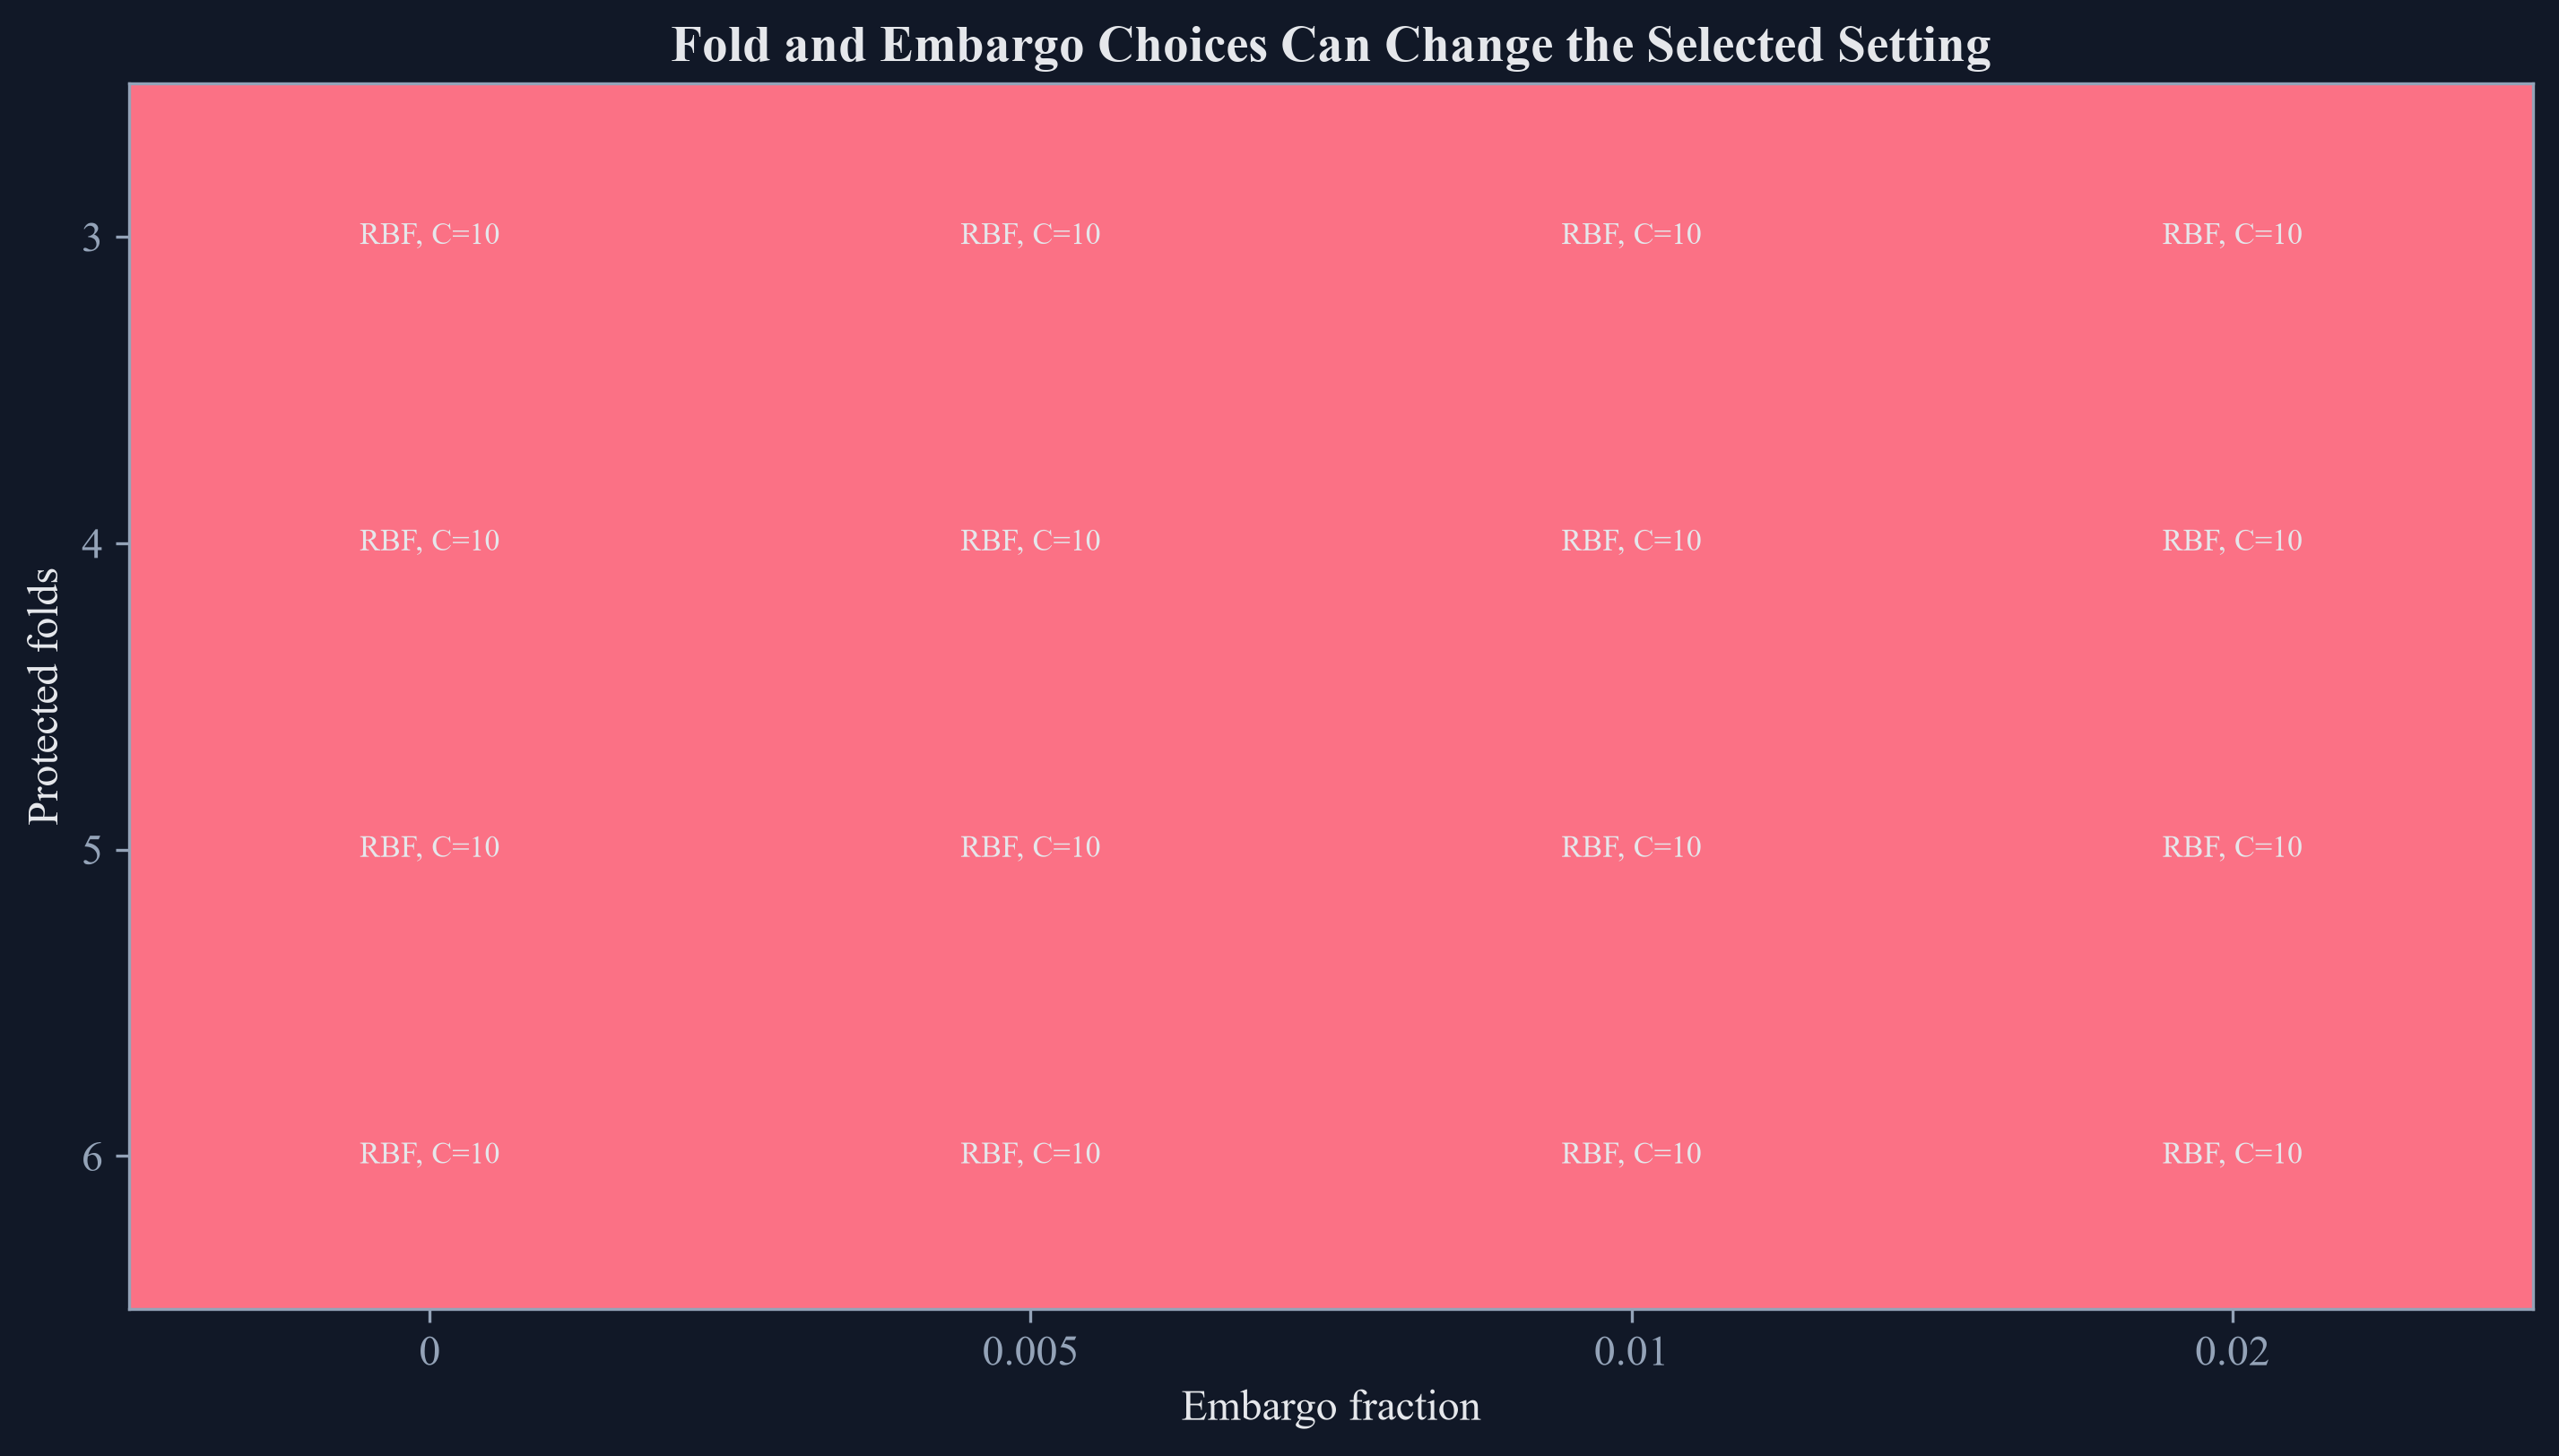

In [3]:
protection_configurations = [(kernel, penalty) for kernel, penalty in product(["linear", "rbf"], [1.0, 10.0])]
protection_records = []
for n_splits in [3, 4, 5, 6]:
    for embargo in [0.0, 0.005, 0.01, 0.02]:
        surface = purged_configuration_scores(public_x, public_y, event_times, protection_configurations, n_splits=n_splits, embargo=embargo, weights=sample_weight)
        best = selected_row(surface)
        runner_up = surface.sort_values(["Mean F1", "Order"], ascending=[False, True]).iloc[1]
        protection_records.append({
            "Folds": n_splits,
            "Embargo fraction": embargo,
            "Selected kernel": best["Kernel"],
            "Selected C": best["C"],
            "Best mean F1": best["Mean F1"],
            "F1 spread": best["F1 spread"],
            "Score margin": best["Mean F1"] - runner_up["Mean F1"],
            "Mean removed observations": best["Mean removed observations"],
        })
protection_sensitivity = pd.DataFrame(protection_records)
protection_selection_frequency = protection_sensitivity.groupby(["Selected kernel", "Selected C"], as_index=False).size().rename(columns={"size": "Selections"})
protection_selection_frequency["Selection share"] = protection_selection_frequency["Selections"] / len(protection_sensitivity)
save_table(protection_sensitivity, "protection_sensitivity", "Selected settings across sixteen fold and embargo choices.", "tab:chapter16-protection-sensitivity")
save_table(protection_selection_frequency, "protection_selection_frequency", "Selection frequencies across fold and embargo choices.", "tab:chapter16-protection-selection-frequency", fit=False)
display(protection_sensitivity)
display(protection_selection_frequency)

setting_labels = [configuration_name(kernel, penalty) for kernel, penalty in protection_configurations]
setting_codes = {name: index for index, name in enumerate(setting_labels)}
matrix = np.zeros((4, 4), dtype=int)
for row, n_splits in enumerate([3, 4, 5, 6]):
    for column, embargo in enumerate([0.0, 0.005, 0.01, 0.02]):
        selected = protection_sensitivity[(protection_sensitivity["Folds"] == n_splits) & np.isclose(protection_sensitivity["Embargo fraction"], embargo)].iloc[0]
        matrix[row, column] = setting_codes[configuration_name(selected["Selected kernel"], selected["Selected C"])]
figure, axis = plt.subplots(figsize=(9.4, 5.3), constrained_layout=True)
image = axis.imshow(matrix, aspect="auto", cmap=ListedColormap([palette["cyan"], palette["amber"], palette["green"], palette["rose"]]), vmin=0, vmax=3)
axis.set_title("Fold and Embargo Choices Can Change the Selected Setting")
axis.set_xlabel("Embargo fraction")
axis.set_ylabel("Protected folds")
axis.set_xticks(np.arange(4))
axis.set_xticklabels(["0", "0.005", "0.01", "0.02"])
axis.set_yticks(np.arange(4))
axis.set_yticklabels(["3", "4", "5", "6"])
for row in range(matrix.shape[0]):
    for column in range(matrix.shape[1]):
        axis.text(column, row, setting_labels[matrix[row, column]], ha="center", va="center", color=palette["text"], fontsize=8.2)
figure.savefig(FIGURES / "protection_selection_map.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "protection_selection_map.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "protection_selection_map.png")))
plt.close(figure)

The winning margin in history $m$ is the difference between its best and second-best protected scores:

$$
M_m=\overline s_m^{(1)}-\overline s_m^{(2)}.
$$

Here, $\overline s_m^{(1)}$ is the largest protected mean score in history $m$, $\overline s_m^{(2)}$ is the second largest, and $M_m$ is the score margin. A small margin means that a minor score change could reverse the choice.

## Stability Summary

In [4]:
expanding_probabilities = expanding_selection_frequency["Selection share"].to_numpy()
expanding_entropy = -float(np.sum(expanding_probabilities * np.log(expanding_probabilities))) / np.log(len(stability_configurations))
protection_probabilities = protection_selection_frequency["Selection share"].to_numpy()
protection_entropy = -float(np.sum(protection_probabilities * np.log(protection_probabilities))) / np.log(len(protection_configurations))
adjacent_changes = int(np.sum((expanding_history_selections["Selected kernel"].to_numpy()[1:] != expanding_history_selections["Selected kernel"].to_numpy()[:-1]) | (expanding_history_selections["Selected C"].to_numpy()[1:] != expanding_history_selections["Selected C"].to_numpy()[:-1])))
stability_summary = pd.DataFrame({
    "Quantity": ["Expanding histories", "Distinct expanding-history selections", "Most common expanding selection share", "Expanding selection entropy", "Adjacent selection changes", "Mean expanding score margin", "Smallest expanding score margin", "Fold and embargo designs", "Distinct protection-design selections", "Protection-design selection entropy"],
    "Value": [len(expanding_history_selections), len(expanding_selection_frequency), expanding_selection_frequency["Selection share"].max(), expanding_entropy, adjacent_changes, expanding_history_selections["Score margin"].mean(), expanding_history_selections["Score margin"].min(), len(protection_sensitivity), len(protection_selection_frequency), protection_entropy],
})
save_table(stability_summary, "stability_summary", "Selection-stability summary for the public experiment.", "tab:chapter16-stability-summary", fit=False)
display(stability_summary)

,Quantity,Value
0,Expanding histories,7
1,Distinct expanding-history selections,3
2,Most common expanding selection share,0.428571
3,Expanding selection entropy,0.518886
4,Adjacent selection changes,4
5,Mean expanding score margin,0.033100
6,Smallest expanding score margin,0
7,Fold and embargo designs,16
8,Distinct protection-design selections,1
9,Protection-design selection entropy,0


## Tests

In [5]:
assert len(history_sizes) == 7
assert history_sizes[-1] == len(public_x)
assert expanding_history_selections.shape == (7, 8)
assert expanding_history_surface.shape == (56, 7)
assert expanding_history_selections['Best mean F1'].between(0, 1).all()
assert expanding_history_selections['Second mean F1'].between(0, 1).all()
assert expanding_history_selections['Score margin'].ge(0).all()
assert expanding_selection_frequency['Selections'].sum() == 7
assert np.isclose(expanding_selection_frequency['Selection share'].sum(), 1)
assert 0 <= expanding_entropy <= 1
assert score_pivot.shape == (8, 7)
assert protection_sensitivity.shape == (16, 8)
assert protection_sensitivity['Best mean F1'].between(0, 1).all()
assert protection_sensitivity['Score margin'].ge(0).all()
assert protection_sensitivity['Mean removed observations'].ge(0).all()
assert protection_selection_frequency['Selections'].sum() == 16
assert np.isclose(protection_selection_frequency['Selection share'].sum(), 1)
assert 0 <= protection_entropy <= 1
assert matrix.shape == (4, 4)
assert np.isin(matrix, np.arange(4)).all()
assert 0 <= adjacent_changes <= 6
assert stability_summary.shape == (10, 2)
assert (FIGURES / 'expanding_history_stability.pdf').is_file()
assert (FIGURES / 'expanding_score_surface.pdf').is_file()
assert (FIGURES / 'protection_selection_map.pdf').is_file()
assert (TABLES / 'expanding_history_selections.tex').is_file()
assert (TABLES / 'expanding_history_surface.tex').is_file()
assert (TABLES / 'expanding_selection_frequency.tex').is_file()
assert (TABLES / 'protection_sensitivity.tex').is_file()
assert (TABLES / 'protection_selection_frequency.tex').is_file()
assert (TABLES / 'stability_summary.tex').is_file()
